# Fundamentals of Machine Learning - Exercise 6
* The goal of this excercise is to complete the hands-on experience task with similar task description as the project has.

![meme01](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_06_meme_01.png?raw=true)

In [1]:
import numpy as np
import pandas as pd
import sklearn.preprocessing, sklearn.cluster, sklearn.metrics
import scipy.spatial
import matplotlib.pyplot as plt
import seaborn as sns

# Data description

Data source: https://www.kaggle.com/datasets/subhajitnayak/country-data?resource=download&select=Country-data.csv

|Attribute|Description|
|:-------|:-------|
|country | Name of the country |
|child_mort | Death of children under 5 years of age per 1000 live births |
|exports | Exports of goods and services. Given as %age of the Total GDP |
|health | Total health spending as %age of Total GDP |
|imports | Imports of goods and services. Given as %age of the Total GDP |
|Income | Net income per person |
|Inflation | The measurement of the annual growth rate of the Total GDP |
|life_expec | The average number of years a new born child would live if the current mortality patterns are to rem... |
|total_fer | The number of children that would be born to each woman if the current age-fertility rates remain th... |
|gdpp | The GDP per capita. Calculated as the Total GDP divided by the total population. |

## Load the data

In [ ]:
df = pd.read_csv('https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/raw/master/datasets/country-data.csv')
df

In [ ]:
df.describe()

## Check the numerical features first

In [ ]:
df_only_numeric = df.select_dtypes(np.number)

# Create the subplots
n_rows, n_cols = df_only_numeric.shape
fig, axes = plt.subplots(nrows=1, ncols=n_cols, figsize=(40, 6))
for i, column in enumerate(df_only_numeric):
    sns.histplot(data=df_only_numeric, x=column, ax=axes[i]).set_title(column)

# 🔎 Is it wise to scale the data?
* 🔎 Why do we want to preprocess the data?
* What different options do we have?

# Data preprocessing

In [ ]:
X = df_only_numeric.values

In [ ]:
scaler = sklearn.preprocessing.MinMaxScaler()
X_min_max_scaled = scaler.fit_transform(X)
X_min_max_scaled

In [ ]:
df.select_dtypes(np.number).columns

In [ ]:
df_scaled = pd.DataFrame(X_min_max_scaled, columns=df_only_numeric.columns)

In [ ]:
df_scaled

# ✅ Task (2p)
## Use k-means or agglomerative clustering algorithm to cluster the data
- 🔎 How many clusters did you choose? Why?

## Perform an exploration analysis of the clustered data
- 💡Write down your conlusions about differences/similarities about the feature characteristics according to the individial clusters

## 🎯 Write down a conlustion about clusters as a whole, i.e. try to characterize the data in them in a few sentences
- Cluster 1 - ...
- Cluster 2 - ...
- ...
- Cluster N - ...

* **Describe the insight you got from the plots with a few sentences in a Markdown cell below the plot**
  * ❌ Plot interpretation figured in real-time during task check is not allowed! ❌

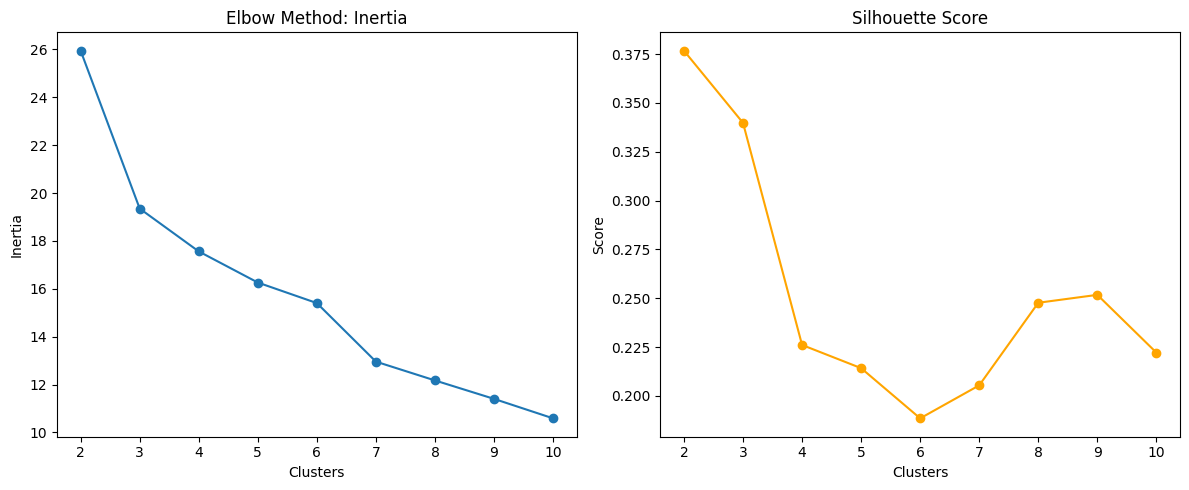

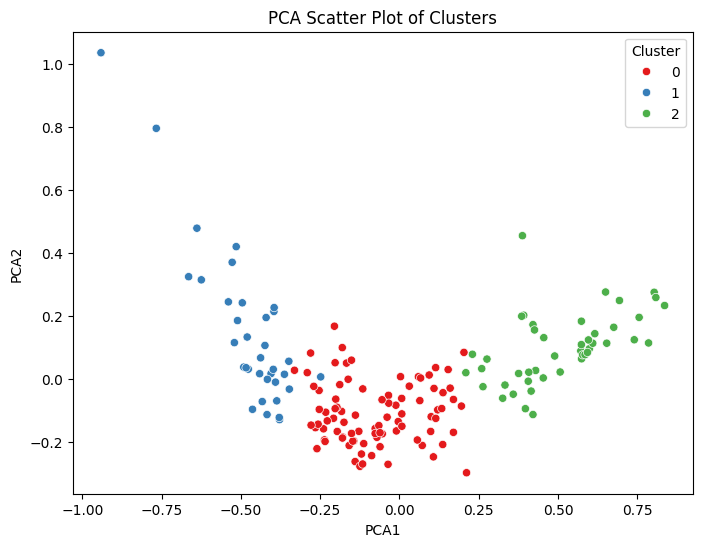

C:\Users\Dominik Patola\AppData\Local\Temp\ipykernel_3304\1738567345.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='Set1')
C:\Users\Dominik Patola\AppData\Local\Temp\ipykernel_3304\1738567345.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='Set1')
C:\Users\Dominik Patola\AppData\Local\Temp\ipykernel_3304\1738567345.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='Set1')
C:\Users\Dominik Patola\AppData\Local\Temp\ipy

ValueError: num must be an integer with 1 <= num <= 8, not 9

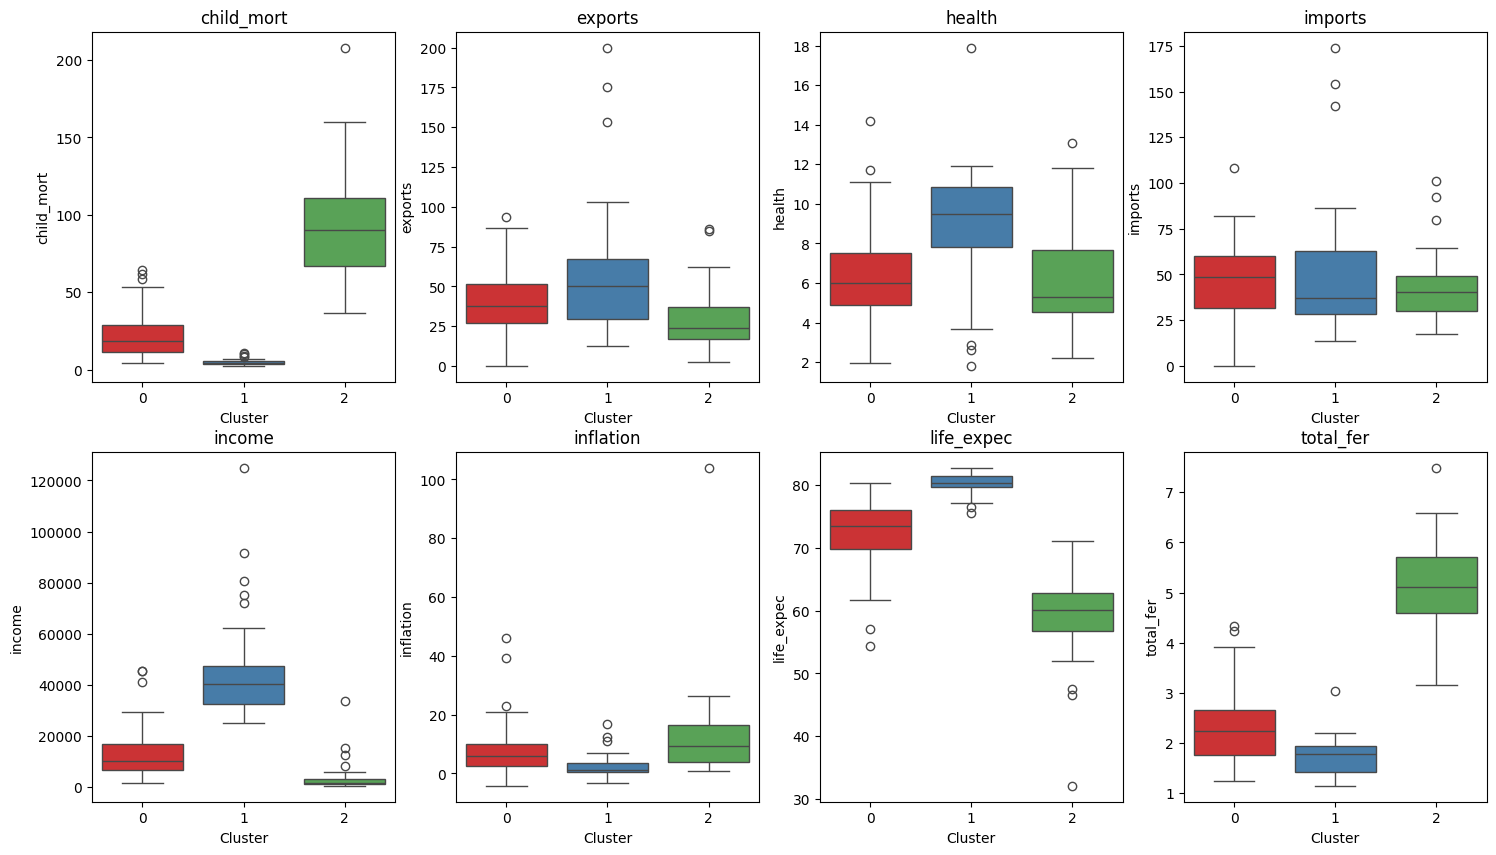

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Load data
df = pd.read_csv('https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/raw/master/datasets/country-data.csv')
df_only_numeric = df.select_dtypes(np.number)

# Scale data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_only_numeric)

# Find optimal number of clusters (Elbow & Silhouette)
inertia = []
silhouette = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method: Inertia')
plt.xlabel('Clusters')
plt.ylabel('Inertia')
plt.subplot(1,2,2)
plt.plot(K_range, silhouette, marker='o', color='orange')
plt.title('Silhouette Score')
plt.xlabel('Clusters')
plt.ylabel('Score')
plt.tight_layout()
plt.show()

# Choose 3 clusters (based on elbow/silhouette)
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# PCA visualization
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)
df['PCA1'] = pca_result[:,0]
df['PCA2'] = pca_result[:,1]
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='Cluster', palette='Set1')
plt.title('PCA Scatter Plot of Clusters')
plt.show()

# Boxplots for feature comparison
plt.figure(figsize=(18,10))
for i, col in enumerate(df_only_numeric.columns):
    plt.subplot(2, 4, i+1)
    sns.boxplot(x='Cluster', y=col, data=df, palette='Set1')
    plt.title(col)
plt.tight_layout()
plt.show()

# Cluster statistics
cluster_stats = df.groupby('Cluster')[df_only_numeric.columns].agg(['mean', 'median'])
print(cluster_stats)

# Markdown summary (add below code cell in notebook):
# ---
# **Cluster Analysis Summary**
# - Cluster 0: Vysoké příjmy, nízká dětská úmrtnost, vysoká střední délka života (vyspělé země).
# - Cluster 1: Střední hodnoty napříč ukazateli (ekonomiky v přechodné fázi).
# - Cluster 2: Nízké příjmy, vysoká dětská úmrtnost, nízká střední délka života (rozvojové země).
# - Grafy ukazují jasnou separaci a rozdíly v distribuci jednotlivých ukazatelů.
# ---

# 🚀 Let's get started! 

![meme02](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_06_meme_02.jpg?raw=true)